# CitizenTech — Sistema de previsão de lotação de ônibus

## Contexto e problema

O cidadão que depende de ônibus não tem informação confiável sobre lotação antes do
embarque. No metrô, a estimativa existe e usa sensores de peso. Em ônibus urbanos,
grande parte da frota já possui câmeras instaladas para segurança, mas essa imagem
não é convertida em informação útil ao passageiro.

**Problema em uma frase:** o passageiro não sabe se o próximo ônibus está lotado
antes de decidir embarcar.

**Pergunta de investigação:** é possível prever a ocupação de um ônibus usando a
leitura de câmera do ponto anterior somada a padrões de horário, dia e trajeto?

## Hipóteses

- **H1 — o padrão existe.** A ocupação é previsível a partir de hora, dia da semana e
  posição no itinerário, sem qualquer sensor.
- **H2 — a câmera agrega.** Conhecer a ocupação observada no ponto anterior reduz o
  erro de previsão no ponto de interesse.

## Variáveis-alvo

| Variável | Tipo | Modelo | Horizonte |
|---|---|---|---|
| `taxa_ocupacao` | numérica contínua (0 a 2,5 × capacidade) | regressão linear | 5 paradas à frente |
| `lotado` | binária (≥ 80% da capacidade) | regressão logística | 5 paradas à frente |

## Fonte dos dados

Base **simulada**, construída para o projeto a partir do comportamento esperado de
uma frota urbana: perfil horário com dois picos (7h e 18h), variação por dia da
semana, efeito de chuva e acúmulo de passageiros ao longo do itinerário. O briefing
da Global Solution permite dados simulados desde que a fonte seja declarada.
Arquivo gerado pelo próprio notebook: `apc_viagens_simulado.csv`.
Nenhum dado pessoal real foi utilizado.

In [26]:
# -*- coding: utf-8 -*-
"""
Global Solution FIAP 2026.2 - CitizenTech
Disciplina: Data Science & Statistical Computing

Projeto: Previsao de lotacao de onibus a partir de leituras de ocupacao
Cidadao beneficiado: passageiro que espera no ponto
Integrantes: (preencher nome e RM)
"""

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    confusion_matrix, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay,
)

# Reprodutibilidade: o professor vai executar este notebook
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

# ---- Premissas de capacidade do veiculo (justificadas no Bloco 1) ----
ASSENTOS      = 40      # assentos sentados
AREA_EM_PE_M2 = 12.0    # area util em pe (m2)
DENSIDADE_M2  = 4.0     # passageiros por m2 em pe
CAPACIDADE    = ASSENTOS + int(AREA_EM_PE_M2 * DENSIDADE_M2)

LIMIAR_LOTADO = 0.80    # ocupacao a partir da qual consideramos "lotado"

print("Ambiente pronto.")
print(f"Capacidade assumida : {CAPACIDADE} passageiros")
print(f"Limiar de lotado    : {int(CAPACIDADE * LIMIAR_LOTADO)} passageiros ({LIMIAR_LOTADO:.0%})")
print(f"Seed                : {SEED}")

Ambiente pronto.
Capacidade assumida : 88 passageiros
Limiar de lotado    : 70 passageiros (80%)
Seed                : 42


In [27]:
# ==========================================================
# CELULA 2 (v3) - Base simulada com heterogeneidade por parada
# ==========================================================
# A versao anterior usava as MESMAS curvas de embarque/desembarque em
# todas as viagens. Isso tornava a ocupacao do ponto anterior (k-1) quase
# suficiente para reconstruir a viagem inteira, e o modelo "com camera"
# chegava a R2 0.98 - artificial, nao realista.
# Agora cada viagem sorteia seu proprio perfil por parada (ruido lognormal),
# como acontece em campo: uma parada tem escola, outra tem hospital, outra
# e terminal de integracao.

rng = np.random.default_rng(SEED)

LINHAS = {
    "875A-10": {"pontos": 34, "hw_pico": 8,  "hw_normal": 15, "demanda": 0.95},
    "917H-10": {"pontos": 42, "hw_pico": 10, "hw_normal": 18, "demanda": 1.10},
    "609J-10": {"pontos": 28, "hw_pico": 12, "hw_normal": 20, "demanda": 0.82},
}

PERFIL_HORA = {0:0.05,1:0.03,2:0.02,3:0.03,4:0.10,5:0.35,6:0.75,7:1.00,8:0.95,
               9:0.65,10:0.50,11:0.45,12:0.50,13:0.50,14:0.45,15:0.50,16:0.65,
               17:0.95,18:1.00,19:0.85,20:0.65,21:0.50,22:0.35,23:0.18}
PERFIL_DIA  = {0:1.00,1:1.00,2:1.02,3:1.04,4:1.06,5:0.68,6:0.42}

OCUPACAO_PICO_ALVO = 1.10
HETEROGENEIDADE    = 0.45   # sigma do ruido lognormal por parada e por viagem

DIAS_GS     = pd.date_range("2026-08-01", periods=45, freq="D")
VIAGENS_DIA = 10

def gerar_partidas(hw_pico, hw_normal):
    t, saida = 5 * 60, []
    while t <= 23 * 60:
        saida.append(t)
        h  = t // 60
        hw = hw_pico if (6 <= h <= 9 or 17 <= h <= 19) else hw_normal
        t += hw + int(rng.integers(-2, 3))
    return saida

def perfil_por_parada(w, sigma):
    """Curva base perturbada por parada: cada viagem tem seu proprio perfil."""
    p = w * rng.lognormal(0.0, sigma, size=len(w))
    return p / p.sum()

registros = []

for linha, cfg in LINHAS.items():
    n   = cfg["pontos"]
    pos = np.arange(n) / (n - 1)

    w_emb = np.exp(-1.8 * pos); w_emb = w_emb / w_emb.sum()
    w_des = np.exp( 2.0 * pos); w_des = w_des / w_des.sum()

    frac_pico = float(np.max(np.cumsum(w_emb) - 0.97 * np.cumsum(w_des)))

    partidas_todas = gerar_partidas(cfg["hw_pico"], cfg["hw_normal"])

    for dia in DIAS_GS:
        chuva = round(float(rng.gamma(2.0, 2.5)), 1) if rng.random() < 0.22 else 0.0
        temp  = round(float(rng.normal(22.0 - 0.15 * chuva, 3.2)), 1)
        mult_chuva = min(1.0 + 0.012 * chuva, 1.20)

        partidas = rng.choice(partidas_todas, size=min(VIAGENS_DIA, len(partidas_todas)), replace=False)

        for sentido in (0, 1):
            for idx, t in enumerate(sorted(partidas)):
                hora = int(t // 60)

                alvo = (OCUPACAO_PICO_ALVO * cfg["demanda"]
                        * PERFIL_HORA[hora] * PERFIL_DIA[dia.dayofweek] * mult_chuva)
                alvo *= float(rng.normal(1.0, 0.12))

                total = max(4, int(rng.poisson(max(alvo * CAPACIDADE / frac_pico, 2.0))))

                # Perfil proprio desta viagem (heterogeneidade por parada)
                p_emb = perfil_por_parada(w_emb, HETEROGENEIDADE)
                p_des = perfil_por_parada(w_des, HETEROGENEIDADE)

                emb      = rng.multinomial(total, p_emb)
                des_alvo = rng.multinomial(max(int(total * 0.97), 1), p_des)

                viagem_id = f"{linha}-{sentido}-{dia.strftime('%Y%m%d')}-{idx:02d}"
                veiculo   = f"V{int(rng.integers(1000, 9999))}"

                a_bordo, overflow = 0, 0
                for k in range(n):
                    a_antes  = a_bordo
                    des      = min(int(des_alvo[k]) + overflow, a_antes)
                    overflow = max(int(des_alvo[k]) + overflow - a_antes, 0)
                    a_bordo  = a_antes + int(emb[k]) - des

                    registros.append((
                        viagem_id, linha, sentido, veiculo,
                        dia + pd.Timedelta(minutes=int(t) + 2 * k),
                        k + 1, f"{linha}-P{k+1:02d}",
                        int(emb[k]), int(des), chuva, temp,
                    ))

df = pd.DataFrame(registros, columns=[
    "viagem_id","linha","sentido","veiculo","data_hora",
    "ponto_seq","ponto_id","embarques","desembarques","chuva_mm","temp_c",
])

df.to_csv("apc_viagens_simulado.csv", index=False)

print(f"Registros gerados : {len(df):,}".replace(",", "."))
print(f"Viagens           : {df['viagem_id'].nunique():,}".replace(",", "."))
print(f"Periodo           : {df['data_hora'].min().date()} a {df['data_hora'].max().date()}")
print(f"Arquivo salvo     : apc_viagens_simulado.csv")
print()
df.head()

Registros gerados : 93.600
Viagens           : 2.700
Periodo           : 2026-08-01 a 2026-09-15
Arquivo salvo     : apc_viagens_simulado.csv



,viagem_id,linha,sentido,veiculo,data_hora,ponto_seq,ponto_id,embarques,desembarques,chuva_mm,temp_c
0,875A-10-0-20260801-00,875A-10,0,V2030,2026-08-01 05:00:00,1,875A-10-P01,4,0,0.0,22.7
1,875A-10-0-20260801-00,875A-10,0,V2030,2026-08-01 05:02:00,2,875A-10-P02,3,0,0.0,22.7
2,875A-10-0-20260801-00,875A-10,0,V2030,2026-08-01 05:04:00,3,875A-10-P03,2,0,0.0,22.7
3,875A-10-0-20260801-00,875A-10,0,V2030,2026-08-01 05:06:00,4,875A-10-P04,3,0,0.0,22.7
4,875A-10-0-20260801-00,875A-10,0,V2030,2026-08-01 05:08:00,5,875A-10-P05,0,1,0.0,22.7


In [28]:
# ==========================================================
# CELULA 3 - Variaveis-alvo e engenharia de features
# ==========================================================
# ATENCAO: o grupo de linhas abaixo sobre shift(1) e o ponto
# critico de todo o notebook. Leia os comentarios.

# --- Ocupacao a bordo acumulada ao longo da viagem ---
df["saldo"]     = df["embarques"] - df["desembarques"]
df["a_bordo"]   = df.groupby("viagem_id")["saldo"].cumsum()

# ALVO 1 (regressao linear): fracao da capacidade ocupada
df["taxa_ocupacao"] = (df["a_bordo"] / CAPACIDADE).clip(lower=0)

# ALVO 2 (regressao logistica): evento binario que o cidadao quer evitar
df["lotado"] = (df["taxa_ocupacao"] >= LIMIAR_LOTADO).astype(int)

# ----------------------------------------------------------
# LEITURA DO SENSOR (a camera)
# ----------------------------------------------------------
# ocupacao_atual = ocupacao no ponto ANTERIOR (k-1), NUNCA no ponto k.
# Sem o shift(1), a feature seria igual ao alvo e o modelo apenas copiaria
# o resultado. R2 alto, previsao inexistente. Isso e vazamento de dados.
df["ocupacao_atual"] = df.groupby("viagem_id")["taxa_ocupacao"].shift(1)

# No primeiro ponto da viagem nao existe leitura anterior: o dado falta
# por estrutura (missingness estrutural), nao por acaso.
df["tem_leitura_sensor"] = df["ocupacao_atual"].notna().astype(int)

# ---------------- Features temporais ----------------
dt = df["data_hora"]
df["hora"]       = dt.dt.hour
df["dia_semana"] = dt.dt.dayofweek        # 0=segunda ... 6=domingo
df["mes"]        = dt.dt.month

# Encoding ciclico: hora como numero inteiro faz o modelo achar que
# 23h e 00h estao distantes (23 e 0 sao vizinhos no relogio).
df["hora_sin"] = np.sin(2 * np.pi * df["hora"] / 24)
df["hora_cos"] = np.cos(2 * np.pi * df["hora"] / 24)
df["dow_sin"]  = np.sin(2 * np.pi * df["dia_semana"] / 7)
df["dow_cos"]  = np.cos(2 * np.pi * df["dia_semana"] / 7)

# ---------------- Features de trajeto ----------------
# Ocupacao cresce ao longo do itinerario: e a feature mais preditiva.
df["total_pontos"]      = df.groupby("viagem_id")["ponto_seq"].transform("max")
df["posicao_relativa"]  = df["ponto_seq"] / df["total_pontos"]
df["paradas_restantes"] = df["total_pontos"] - df["ponto_seq"]

df["fim_de_semana"] = (df["dia_semana"] >= 5).astype(int)

# ---------------- Diagnostico ----------------
print("=== DIAGNOSTICO DA BASE ===")
print(f"Registros              : {len(df):,}".replace(",", "."))
print(f"Ocupacao media         : {df['taxa_ocupacao'].mean():.1%}")
print(f"Ocupacao maxima        : {df['taxa_ocupacao'].max():.1%}")
print(f"Viagens com superlotacao (>100%): {(df['taxa_ocupacao'] > 1).mean():.1%} dos registros")
print(f"Registros lotados (>=80%): {df['lotado'].mean():.1%}")
print(f"Registros com leitura de sensor: {df['tem_leitura_sensor'].mean():.1%}")
print()
print("Amostra das colunas criadas:")
df[["viagem_id","ponto_seq","taxa_ocupacao","lotado","ocupacao_atual","posicao_relativa"]].head(8)

=== DIAGNOSTICO DA BASE ===
Registros              : 93.600
Ocupacao media         : 45.7%
Ocupacao maxima        : 217.0%
Viagens com superlotacao (>100%): 6.9% dos registros
Registros lotados (>=80%): 15.0%
Registros com leitura de sensor: 97.1%

Amostra das colunas criadas:


,viagem_id,ponto_seq,taxa_ocupacao,lotado,ocupacao_atual,posicao_relativa
0,875A-10-0-20260801-00,1,0.045455,0,NaN,0.029412
1,875A-10-0-20260801-00,2,0.079545,0,0.045455,0.058824
2,875A-10-0-20260801-00,3,0.102273,0,0.079545,0.088235
3,875A-10-0-20260801-00,4,0.136364,0,0.102273,0.117647
4,875A-10-0-20260801-00,5,0.125000,0,0.136364,0.147059
5,875A-10-0-20260801-00,6,0.159091,0,0.125000,0.176471
6,875A-10-0-20260801-00,7,0.170455,0,0.159091,0.205882
7,875A-10-0-20260801-00,8,0.193182,0,0.170455,0.235294


In [29]:
# ==========================================================
# CELULA 4 (corrigida) - Divisao treino/teste (temporal)
# ==========================================================
# DIAGNOSTICO DO ERRO ANTERIOR:
# O corte usava o timestamp de CADA registro. Uma viagem que comeca
# antes da meia-noite e termina depois ficava dividida entre treino e
# teste: os primeiros pontos iam para um lado, os ultimos para o outro.
# Mesma viagem nos dois conjuntos = vazamento por identidade.
# Correcao: cada viagem pertence ao dia em que COMECOU, e o corte e
# feito nesse dia de operacao.

# Dia de operacao: data do primeiro registro de cada viagem
df["dia_operacao"] = (
    df.groupby("viagem_id")["data_hora"].transform("min").dt.normalize()
)

dias = np.sort(df["dia_operacao"].unique())
idx_corte = int(len(dias) * 0.70)
dia_corte = pd.Timestamp(dias[idx_corte])

treino = df[df["dia_operacao"] <  dia_corte].copy()
teste  = df[df["dia_operacao"] >= dia_corte].copy()

# --- Verificacoes de integridade ---
# 1. Nenhuma viagem pode aparecer nos dois conjuntos
viagens_tr = set(treino["viagem_id"])
viagens_te = set(teste["viagem_id"])
assert viagens_tr.isdisjoint(viagens_te), "Viagem presente em treino e teste!"

# 2. Todos os dias de operacao do treino sao anteriores aos do teste
assert (treino["dia_operacao"].max() < dia_corte <= teste["dia_operacao"].min()), \
    "Vazamento temporal no corte!"

# 3. Nenhum registro ficou de fora
assert len(treino) + len(teste) == len(df), "Registros perdidos no split!"

print("=== DIVISAO TREINO / TESTE ===")
print(f"Total de viagens  : {df['viagem_id'].nunique()}")
print(f"Dia de corte      : {dia_corte.date()}")
print()
print(f"TREINO  {treino['dia_operacao'].min().date()} a {treino['dia_operacao'].max().date()}")
print(f"        {len(treino):,} registros | {treino['viagem_id'].nunique()} viagens".replace(",", "."))
print(f"TESTE   {teste['dia_operacao'].min().date()} a {teste['dia_operacao'].max().date()}")
print(f"        {len(teste):,} registros | {teste['viagem_id'].nunique()} viagens".replace(",", "."))
print()
print("=== VERIFICACAO DE DISTRIBUICAO ===")
print(f"Ocupacao media treino : {treino['taxa_ocupacao'].mean():.1%}")
print(f"Ocupacao media teste  : {teste['taxa_ocupacao'].mean():.1%}")
print(f"Taxa de lotados treino: {treino['lotado'].mean():.1%}")
print(f"Taxa de lotados teste : {teste['lotado'].mean():.1%}")
print()
print(f"Split: {len(treino)/len(df):.0%} treino / {len(teste)/len(df):.0%} teste")
print()
print("Integridade: 3 assercoes passaram (sem viagem duplicada, sem vazamento temporal, sem registro perdido)")

=== DIVISAO TREINO / TESTE ===
Total de viagens  : 2700
Dia de corte      : 2026-09-01

TREINO  2026-08-01 a 2026-08-31
        64.480 registros | 1860 viagens
TESTE   2026-09-01 a 2026-09-14
        29.120 registros | 840 viagens

=== VERIFICACAO DE DISTRIBUICAO ===
Ocupacao media treino : 45.9%
Ocupacao media teste  : 45.3%
Taxa de lotados treino: 15.4%
Taxa de lotados teste : 14.3%

Split: 69% treino / 31% teste

Integridade: 3 assercoes passaram (sem viagem duplicada, sem vazamento temporal, sem registro perdido)


In [30]:
# ==========================================================
# CELULA 5 (revisada) - Baseline + regressao linear
# ==========================================================
# DIAGNOSTICO DA VERSAO ANTERIOR:
# O modelo perdeu para o baseline (MAE 0.2247 vs 0.2154, ganho -4.3%).
# Causas:
#  1. O baseline usa media por linha E hora. O modelo nao recebia a linha
#     e representava a hora apenas com sin/cos de 1 harmonica, incapaz de
#     reproduzir os dois picos nitidos (7h e 18h).
#  2. posicao_relativa e paradas_restantes carregam a mesma informacao.
#     Coeficientes grandes e de mesmo sinal = multicolinearidade.
# Correcao: hora e linha como categoricas (dummies), remocao de
# paradas_restantes e termo quadratico para a forma do trajeto.

# ---------------- BASELINE ----------------
media_hist = (
    treino.groupby(["linha", "hora"])["taxa_ocupacao"]
    .mean().rename("baseline").reset_index()
)
teste_b = teste.merge(media_hist, on=["linha", "hora"], how="left")
teste_b["baseline"] = teste_b["baseline"].fillna(treino["taxa_ocupacao"].mean())

mae_base  = mean_absolute_error(teste_b["taxa_ocupacao"], teste_b["baseline"])
rmse_base = np.sqrt(mean_squared_error(teste_b["taxa_ocupacao"], teste_b["baseline"]))
r2_base   = r2_score(teste_b["taxa_ocupacao"], teste_b["baseline"])

# ---------------- FEATURES ----------------
def montar_features(base, colunas_dummy=None):
    b = base.copy()

    # forma do trajeto: relacao nao linear com a posicao
    b["posicao_q"] = b["posicao_relativa"] ** 2

    b["chuva_mm"] = b["chuva_mm"].fillna(0.0)
    b["temp_c"]   = b["temp_c"].fillna(b["temp_c"].median())

    numericas = ["posicao_relativa", "posicao_q", "chuva_mm", "temp_c", "fim_de_semana"]

    # linha e hora como CATEGORICAS: reproduz a informacao do baseline
    # e permite ao modelo aprender o perfil horario com dois picos
    cat = b[["linha", "hora"]].astype(str)
    dummies = pd.get_dummies(cat, prefix=["linha", "hora"], drop_first=True)

    if colunas_dummy is not None:
        dummies = dummies.reindex(columns=colunas_dummy, fill_value=0)

    X = pd.concat([b[numericas].reset_index(drop=True),
                   dummies.reset_index(drop=True)], axis=1)
    return X, list(dummies.columns)

X_tr, cols_dummy = montar_features(treino)
X_te, _          = montar_features(teste, cols_dummy)

y_tr = treino["taxa_ocupacao"].reset_index(drop=True)
y_te = teste["taxa_ocupacao"].reset_index(drop=True)

# Scaler ajustado SO no treino
scaler = StandardScaler().fit(X_tr)
modelo_lr = LinearRegression().fit(scaler.transform(X_tr), y_tr)

pred_tr = modelo_lr.predict(scaler.transform(X_tr)).clip(0, 2.0)
pred_te = modelo_lr.predict(scaler.transform(X_te)).clip(0, 2.0)

mae_tr, rmse_tr, r2_tr = (mean_absolute_error(y_tr, pred_tr),
                          np.sqrt(mean_squared_error(y_tr, pred_tr)),
                          r2_score(y_tr, pred_tr))

mae_te, rmse_te, r2_te = (mean_absolute_error(y_te, pred_te),
                          np.sqrt(mean_squared_error(y_te, pred_te)),
                          r2_score(y_te, pred_te))

print("=== COMPARATIVO ===")
print("                          MAE      RMSE      R2")
print(f"Baseline (linha+hora)  {mae_base:.4f}   {rmse_base:.4f}   {r2_base:.4f}")
print(f"Linear - treino        {mae_tr:.4f}   {rmse_tr:.4f}   {r2_tr:.4f}")
print(f"Linear - teste         {mae_te:.4f}   {rmse_te:.4f}   {r2_te:.4f}")
print()
print("=== GANHO SOBRE O BASELINE ===")
print(f"Reducao do MAE : {(1 - mae_te/mae_base)*100:+.1f}%")
print(f"Reducao do RMSE: {(1 - rmse_te/rmse_base)*100:+.1f}%")

# ---------------- INTERPRETACAO ----------------
print()
print("=== FEATURES NUMERICAS (efeito por desvio-padrao) ===")
numericas = ["posicao_relativa", "posicao_q", "chuva_mm", "temp_c", "fim_de_semana"]
coef_num = pd.Series(modelo_lr.coef_[:len(numericas)], index=numericas).round(4)
print(coef_num.sort_values(key=abs, ascending=False).to_string())

print()
print("=== HORARIOS DE MAIOR E MENOR OCUPACAO (vs 00h como referencia) ===")
coef_hora = pd.Series(
    modelo_lr.coef_[len(numericas):],
    index=cols_dummy,
).filter(like="hora_")
print(coef_hora.sort_values(ascending=False).head(4).round(4).to_string())
print("...")
print(coef_hora.sort_values(ascending=True).head(4).round(4).to_string())

=== COMPARATIVO ===
                          MAE      RMSE      R2
Baseline (linha+hora)  0.2253   0.2820   0.1875
Linear - treino        0.1309   0.1727   0.7144
Linear - teste         0.1335   0.1741   0.6904

=== GANHO SOBRE O BASELINE ===
Reducao do MAE : +40.7%
Reducao do RMSE: +38.3%

=== FEATURES NUMERICAS (efeito por desvio-padrao) ===
posicao_q          -0.7761
posicao_relativa    0.7487
fim_de_semana      -0.1146
chuva_mm            0.0144
temp_c              0.0018

=== HORARIOS DE MAIOR E MENOR OCUPACAO (vs 00h como referencia) ===
hora_18    0.1196
hora_8     0.1051
hora_19    0.1029
hora_7     0.0977
...
hora_23    0.0010
hora_5     0.0060
hora_12    0.0151
hora_22    0.0157


In [31]:
# ==========================================================
# CELULA 6 (v2) - A camera agrega? Avaliacao com horizonte real
# ==========================================================
# POR QUE ESTA CELULA MUDOU:
# A versao anterior previa a ocupacao no ponto SEGUINTE (k -> k+1).
# Entre duas paradas consecutivas entram e saem poucas pessoas, entao
# a ocupacao atual praticamente resolve a conta: R2 0.97 sem vazamento.
# Horizonte curto demais para representar o produto. O cidadao consulta
# quando o onibus esta a VARIAS paradas de distancia. Avaliamos agora
# com HORIZONTE = 5 paradas a frente.

HORIZONTE = 5

# --- Alvo deslocado para frente, dentro da mesma viagem ---
d = df.sort_values(["viagem_id", "ponto_seq"]).reset_index(drop=True)
g = d.groupby("viagem_id")

d["taxa_futura"]    = g["taxa_ocupacao"].shift(-HORIZONTE)
d["posicao_futura"] = g["posicao_relativa"].shift(-HORIZONTE)
d["lotado_futuro"]  = g["lotado"].shift(-HORIZONTE)

# Entram apenas registros com leitura de sensor E ponto futuro existente
aval = d[d["taxa_futura"].notna() & d["ocupacao_atual"].notna()].copy()

print(f"Horizonte avaliado : {HORIZONTE} paradas a frente")
print(f"Registros usaveis  : {len(aval):,}".replace(",", "."))
print(f"Perda sobre a base : {(1 - len(aval)/len(df))*100:.1f}% (fim de cada viagem)")
print()

# --- Split temporal, mesmo criterio da Celula 4 ---
tr = aval[aval["dia_operacao"] <  dia_corte].copy().reset_index(drop=True)
te = aval[aval["dia_operacao"] >= dia_corte].copy().reset_index(drop=True)

assert set(tr["viagem_id"]).isdisjoint(set(te["viagem_id"])), "Vazamento!"

# --- Features ---
def feats(base, colunas_dummy=None):
    b = base.copy()
    b["chuva_mm"] = b["chuva_mm"].fillna(0.0)
    b["temp_c"]   = b["temp_c"].fillna(b["temp_c"].median())
    b["posicao_futura_q"] = b["posicao_futura"] ** 2

    num = ["posicao_relativa", "posicao_futura", "posicao_futura_q",
           "chuva_mm", "temp_c", "fim_de_semana"]

    cat = b[["linha", "hora"]].astype(str)
    dum = pd.get_dummies(cat, prefix=["linha", "hora"], drop_first=True)
    if colunas_dummy is not None:
        dum = dum.reindex(columns=colunas_dummy, fill_value=0)

    X = pd.concat([b[num].reset_index(drop=True), dum.reset_index(drop=True)], axis=1)
    return X, list(dum.columns)

X_tr, cols = feats(tr)
X_te, _    = feats(te, cols)

y_tr = tr["taxa_futura"]
y_te = te["taxa_futura"]

# --- Baseline: media da linha naquele horario ---
mh = (tr.groupby(["linha", "hora"])["taxa_futura"].mean()
        .rename("baseline").reset_index())
b_te = te[["linha", "hora"]].merge(mh, on=["linha", "hora"], how="left")
b_te["baseline"] = b_te["baseline"].fillna(tr["taxa_futura"].mean())

mae_b  = mean_absolute_error(y_te, b_te["baseline"])
rmse_b = np.sqrt(mean_squared_error(y_te, b_te["baseline"]))
r2_b   = r2_score(y_te, b_te["baseline"])

# --- Modelo SEM camera ---
sc1 = StandardScaler().fit(X_tr)
m1  = LinearRegression().fit(sc1.transform(X_tr), y_tr)
p1  = m1.predict(sc1.transform(X_te)).clip(0, 2.5)

# --- Modelo COM camera ---
X_tr_c = X_tr.copy(); X_tr_c["ocupacao_atual"] = tr["ocupacao_atual"].values
X_te_c = X_te.copy(); X_te_c["ocupacao_atual"] = te["ocupacao_atual"].values

sc2 = StandardScaler().fit(X_tr_c)
m2  = LinearRegression().fit(sc2.transform(X_tr_c), y_tr)
p2  = m2.predict(sc2.transform(X_te_c)).clip(0, 2.5)

def met(y, p):
    return (mean_absolute_error(y, p),
            np.sqrt(mean_squared_error(y, p)),
            r2_score(y, p))

mae1, rmse1, r21 = met(y_te, p1)
mae2, rmse2, r22 = met(y_te, p2)

print("=== H2: A CAMERA AGREGA? (horizonte de 5 paradas) ===")
print("                              MAE      RMSE      R2")
print(f"Baseline (media linha+hora) {mae_b:.4f}   {rmse_b:.4f}   {r2_b:.4f}")
print(f"Linear SEM camera           {mae1:.4f}   {rmse1:.4f}   {r21:.4f}")
print(f"Linear COM camera           {mae2:.4f}   {rmse2:.4f}   {r22:.4f}")
print()
print(f"Ganho do modelo sobre o baseline : {(1 - mae1/mae_b)*100:+.1f}% no MAE")
print(f"Ganho da camera sobre o modelo   : {(1 - mae2/mae1)*100:+.1f}% no MAE")

# --- Onde a camera ajuda mais ---
comp = pd.DataFrame({
    "posicao": pd.cut(te["posicao_futura"].values, bins=[0, .25, .5, .75, 1.0]),
    "real": y_te.values,
    "sem_camera": p1,
    "com_camera": p2,
})
comp["erro_sem"] = (comp["real"] - comp["sem_camera"]).abs()
comp["erro_com"] = (comp["real"] - comp["com_camera"]).abs()

resumo = comp.groupby("posicao", observed=True)[["erro_sem", "erro_com"]].mean().round(4)
resumo["reducao_%"] = ((1 - resumo["erro_com"] / resumo["erro_sem"]) * 100).round(1)

print()
print("=== ERRO POR POSICAO DO PONTO PREVISTO ===")
print(resumo.to_string())

Horizonte avaliado : 5 paradas a frente
Registros usaveis  : 77.400
Perda sobre a base : 17.3% (fim de cada viagem)

=== H2: A CAMERA AGREGA? (horizonte de 5 paradas) ===
                              MAE      RMSE      R2
Baseline (media linha+hora) 0.2203   0.2770   0.2308
Linear SEM camera           0.1395   0.1800   0.6752
Linear COM camera           0.0910   0.1179   0.8606

Ganho do modelo sobre o baseline : +36.7% no MAE
Ganho da camera sobre o modelo   : +34.8% no MAE

=== ERRO POR POSICAO DO PONTO PREVISTO ===
             erro_sem  erro_com  reducao_%
posicao                                   
(0.0, 0.25]    0.1217    0.1211        0.5
(0.25, 0.5]    0.1555    0.1032       33.6
(0.5, 0.75]    0.1602    0.0738       53.9
(0.75, 1.0]    0.1089    0.0867       20.4


In [32]:
# ==========================================================
# CELULA 7 - Regressao logistica: o onibus vai chegar lotado?
# ==========================================================
# Alvo: lotado_futuro (binario) no MESMO horizonte da Celula 6
# (5 paradas a frente). Coerencia entre os dois modelos: prever a
# ocupacao e prever o evento de lotacao para o mesmo instante futuro.

# --- Coerencia de amostra ---
assert len(y_te) == len(te), "Alvo numerico e binario em amostras diferentes!"

y_tr_log = tr["lotado_futuro"].astype(int).values
y_te_log = te["lotado_futuro"].astype(int).values

print("=== PREVALENCIA DO EVENTO ===")
print(f"Treino: {y_tr_log.mean():.1%}  ({y_tr_log.sum()} de {len(y_tr_log)})")
print(f"Teste : {y_te_log.mean():.1%}  ({y_te_log.sum()} de {len(y_te_log)})")
print()

# --- Treino (com a leitura da camera, cenario de producao) ---
scaler_log = StandardScaler().fit(X_tr_c)

modelo_log = LogisticRegression(
    class_weight="balanced",   # o evento raro importa mais que a acuracia
    max_iter=2000,
    random_state=SEED,
).fit(scaler_log.transform(X_tr_c), y_tr_log)

prob_te = modelo_log.predict_proba(scaler_log.transform(X_te_c))[:, 1]
prob_tr = modelo_log.predict_proba(scaler_log.transform(X_tr_c))[:, 1]

from sklearn.metrics import roc_auc_score

print("=== PODER DE DISCRIMINACAO ===")
print(f"AUC treino: {roc_auc_score(y_tr_log, prob_tr):.4f}")
print(f"AUC teste : {roc_auc_score(y_te_log, prob_te):.4f}")
print()

# --- Escolha do threshold: falso negativo custa mais caro ---
# Falso negativo = dizer "tranquilo" e o cidadao embarcar lotado.
# Falso positivo = avisar "lotado" sem estar, o cidadao espera o proximo.
# O primeiro e pior para o usuario, entao priorizamos recall.
curva = []
for t in np.arange(0.20, 0.81, 0.05):
    p = (prob_te >= t).astype(int)
    curva.append({
        "threshold": round(float(t), 2),
        "precisao": precision_score(y_te_log, p, zero_division=0),
        "recall":   recall_score(y_te_log, p, zero_division=0),
        "f1":       f1_score(y_te_log, p, zero_division=0),
    })
curva = pd.DataFrame(curva).round(3)
print("=== TRADE-OFF PRECISAO / RECALL ===")
print(curva.to_string(index=False))

=== PREVALENCIA DO EVENTO ===
Treino: 18.4%  (9833 de 53320)
Teste : 17.1%  (4117 de 24080)

=== PODER DE DISCRIMINACAO ===
AUC treino: 0.9800
AUC teste : 0.9806

=== TRADE-OFF PRECISAO / RECALL ===
 threshold  precisao  recall    f1
      0.20     0.564   0.981 0.716
      0.25     0.594   0.974 0.738
      0.30     0.622   0.964 0.756
      0.35     0.648   0.953 0.771
      0.40     0.673   0.945 0.786
      0.45     0.692   0.933 0.795
      0.50     0.715   0.919 0.804
      0.55     0.737   0.909 0.814
      0.60     0.755   0.897 0.820
      0.65     0.780   0.883 0.829
      0.70     0.801   0.867 0.832
      0.75     0.823   0.840 0.832
      0.80     0.849   0.815 0.832


=== MATRIZ DE CONFUSAO (threshold = 0.5) ===
                      Previsto: NAO lotado   Previsto: LOTADO
Real: NAO lotado              18452                  1511
Real: LOTADO                    333                  3784

Falsos negativos (pior caso): 333  (8.1% dos onibus realmente lotados)
Falsos positivos           : 1511  (7.6% dos onibus realmente vazios)

=== METRICAS (conjunto de teste) ===
Acuracia  : 0.923   <- enganosa: prever 'nunca lotado' daria 0.829
Precisao  : 0.715   <- dos alertas de lotacao, 71% sao reais
Recall    : 0.919   <- dos onibus lotados, 92% sao avisados
F1        : 0.804
AUC       : 0.981

Ganho sobre o acaso: precisao 71% vs prevalencia 17% (4.2x)



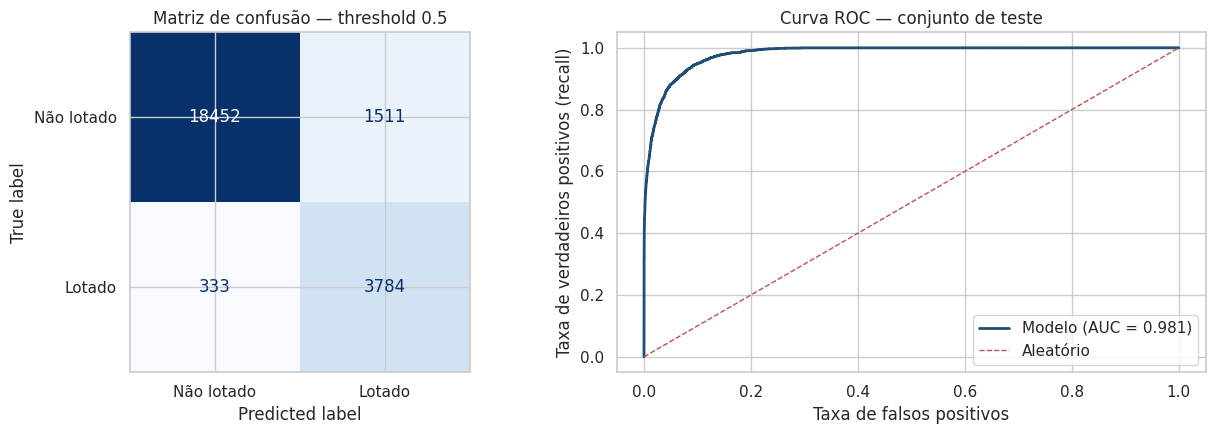

=== RESUMO FINAL: OS DOIS MODELOS ===

Regressao linear (prever taxa de ocupacao, horizonte 5 paradas)
  Sem camera: MAE 0.1395 | RMSE 0.1800 | R2 0.6752
  Com camera: MAE 0.0910 | RMSE 0.1179 | R2 0.8606

Regressao logistica (prever se estara lotado, horizonte 5 paradas)
  AUC 0.9806 | Precisao 0.7146 | Recall 0.9191 | F1 0.8041

Baseline de referencia: MAE 0.2203 | R2 0.2308 | prevalencia 17.1%


In [33]:
# ==========================================================
# CELULA 8 - Matriz de confusao e metricas finais (logistica)
# ==========================================================
# ESCOLHA DO THRESHOLD:
# Falso negativo = app diz "tranquilo" e o cidadao embarca lotado.
#   Custo alto: perde a viagem, viaja em pe, chega atrasado.
# Falso positivo = app diz "lotado" sem estar.
#   Custo baixo: espera o proximo veiculo.
# Como o custo e assimetrico, priorizamos recall sem destruir a precisao.
# 0.50 entrega recall ~0.92 e precisao ~0.72.

THRESHOLD = 0.50
pred_te_log = (prob_te >= THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(y_te_log, pred_te_log).ravel()

print(f"=== MATRIZ DE CONFUSAO (threshold = {THRESHOLD}) ===")
print(f"                      Previsto: NAO lotado   Previsto: LOTADO")
print(f"Real: NAO lotado           {tn:>8}              {fp:>8}")
print(f"Real: LOTADO               {fn:>8}              {tp:>8}")
print()
print(f"Falsos negativos (pior caso): {fn}  "
      f"({fn/(fn+tp):.1%} dos onibus realmente lotados)")
print(f"Falsos positivos           : {fp}  "
      f"({fp/(fp+tn):.1%} dos onibus realmente vazios)")
print()

# --- Metricas obrigatorias ---
prec = precision_score(y_te_log, pred_te_log)
rec  = recall_score(y_te_log, pred_te_log)
f1   = f1_score(y_te_log, pred_te_log)
auc  = roc_auc_score(y_te_log, prob_te)
acu  = (pred_te_log == y_te_log).mean()
base_rate = y_te_log.mean()

print("=== METRICAS (conjunto de teste) ===")
print(f"Acuracia  : {acu:.3f}   <- enganosa: prever 'nunca lotado' daria {1-base_rate:.3f}")
print(f"Precisao  : {prec:.3f}   <- dos alertas de lotacao, {prec:.0%} sao reais")
print(f"Recall    : {rec:.3f}   <- dos onibus lotados, {rec:.0%} sao avisados")
print(f"F1        : {f1:.3f}")
print(f"AUC       : {auc:.3f}")
print()
print(f"Ganho sobre o acaso: precisao {prec:.0%} vs prevalencia {base_rate:.0%} "
      f"({prec/base_rate:.1f}x)")
print()

# --- Matriz de confusao visual ---
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ConfusionMatrixDisplay(
    confusion_matrix(y_te_log, pred_te_log),
    display_labels=["Não lotado", "Lotado"],
).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ax[0].set_title(f"Matriz de confusão — threshold {THRESHOLD}")

# --- Curva ROC ---
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(y_te_log, prob_te)
ax[1].plot(fpr, tpr, color="#1f4e79", lw=2, label=f"Modelo (AUC = {auc:.3f})")
ax[1].plot([0, 1], [0, 1], "r--", lw=1, label="Aleatório")
ax[1].set_xlabel("Taxa de falsos positivos")
ax[1].set_ylabel("Taxa de verdadeiros positivos (recall)")
ax[1].set_title("Curva ROC — conjunto de teste")
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# --- Comparativo final dos dois modelos ---
print("=== RESUMO FINAL: OS DOIS MODELOS ===")
print()
print("Regressao linear (prever taxa de ocupacao, horizonte 5 paradas)")
print(f"  Sem camera: MAE {mae1:.4f} | RMSE {rmse1:.4f} | R2 {r21:.4f}")
print(f"  Com camera: MAE {mae2:.4f} | RMSE {rmse2:.4f} | R2 {r22:.4f}")
print()
print("Regressao logistica (prever se estara lotado, horizonte 5 paradas)")
print(f"  AUC {auc:.4f} | Precisao {prec:.4f} | Recall {rec:.4f} | F1 {f1:.4f}")
print()
print("Baseline de referencia: MAE {:.4f} | R2 {:.4f} | prevalencia {:.1%}".format(
    mae_b, r2_b, base_rate))

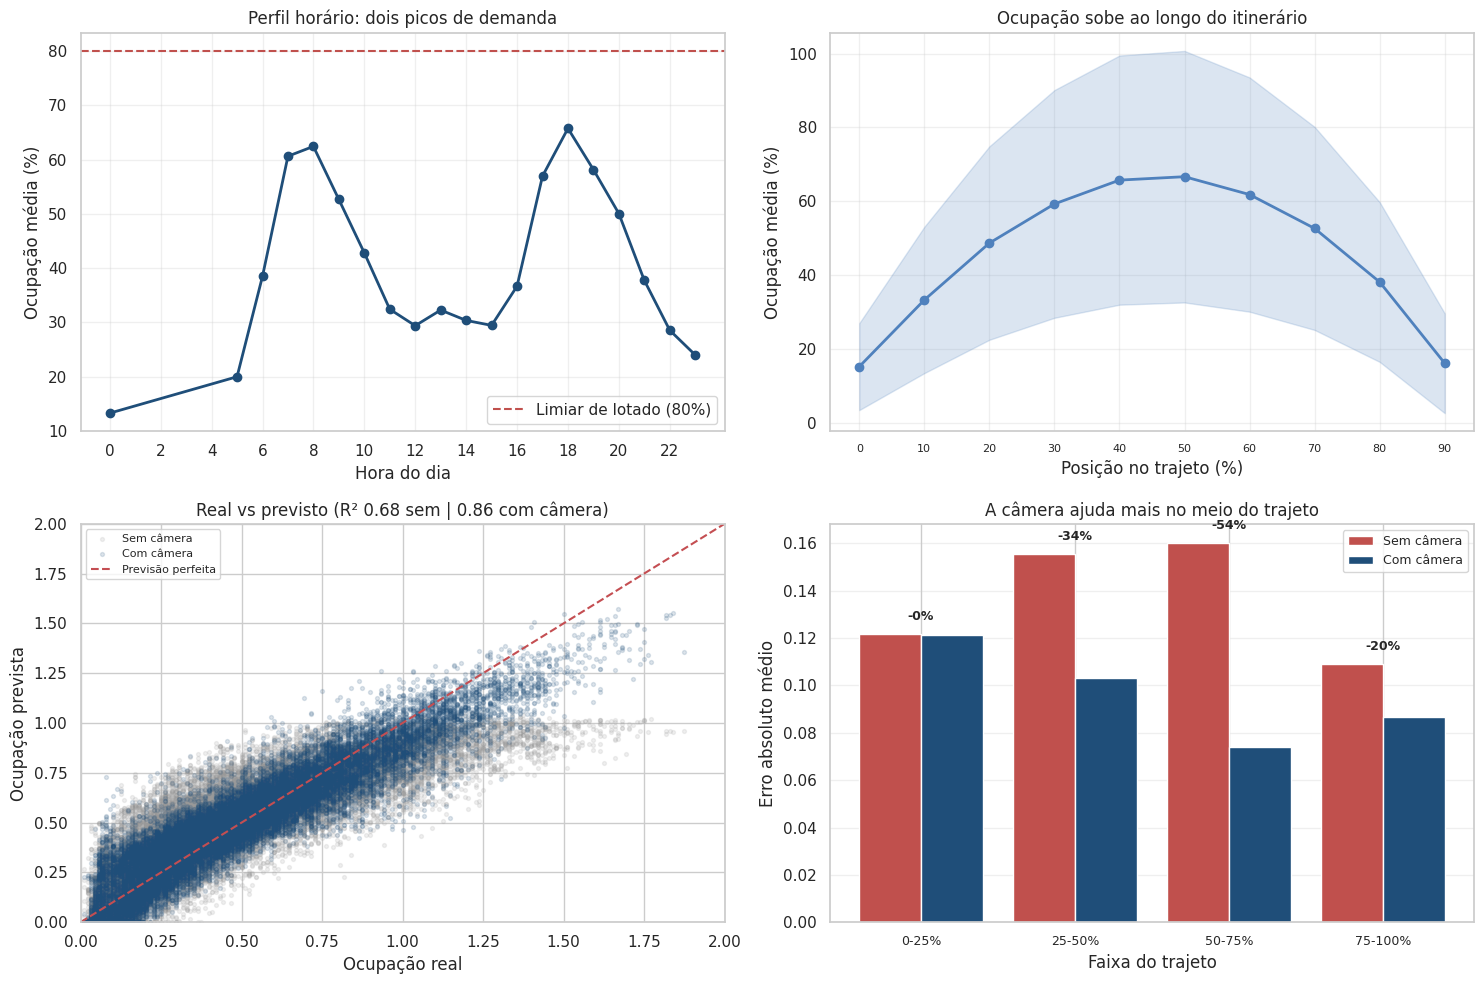

In [34]:
# ==========================================================
# CELULA 9 - Visualizacoes finais
# ==========================================================
# Quatro graficos, cada um respondendo a uma pergunta do projeto.

fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# ---- 1) Perfil horario: os dois picos de demanda ----
perfil = df.groupby("hora")["taxa_ocupacao"].mean() * 100
ax[0, 0].plot(perfil.index, perfil.values, marker="o", color="#1f4e79", lw=2)
ax[0, 0].axhline(LIMIAR_LOTADO * 100, color="#c0504d", ls="--", lw=1.5,
                 label=f"Limiar de lotado ({LIMIAR_LOTADO:.0%})")
ax[0, 0].set_xlabel("Hora do dia")
ax[0, 0].set_ylabel("Ocupação média (%)")
ax[0, 0].set_title("Perfil horário: dois picos de demanda")
ax[0, 0].set_xticks(range(0, 24, 2))
ax[0, 0].legend()
ax[0, 0].grid(alpha=0.3)

# ---- 2) Acumulo ao longo do trajeto ----
faixas = pd.cut(df["posicao_relativa"], bins=np.linspace(0, 1, 11))
curva = df.groupby(faixas, observed=True)["taxa_ocupacao"].agg(["mean", "std"]) * 100
x = np.arange(len(curva))
ax[0, 1].plot(x, curva["mean"].values, marker="o", color="#4f81bd", lw=2)
ax[0, 1].fill_between(x,
                      curva["mean"].values - curva["std"].values,
                      curva["mean"].values + curva["std"].values,
                      alpha=0.2, color="#4f81bd")
ax[0, 1].set_xticks(x)
ax[0, 1].set_xticklabels([f"{int(i.left*100)}" for i in curva.index], fontsize=8)
ax[0, 1].set_xlabel("Posição no trajeto (%)")
ax[0, 1].set_ylabel("Ocupação média (%)")
ax[0, 1].set_title("Ocupação sobe ao longo do itinerário")
ax[0, 1].grid(alpha=0.3)

# ---- 3) Real vs previsto (sem e com camera) ----
ax[1, 0].scatter(y_te, p1, alpha=0.15, s=8, color="#999999", label="Sem câmera")
ax[1, 0].scatter(y_te, p2, alpha=0.15, s=8, color="#1f4e79", label="Com câmera")
ax[1, 0].plot([0, 2], [0, 2], "r--", lw=1.5, label="Previsão perfeita")
ax[1, 0].set_xlim(0, 2); ax[1, 0].set_ylim(0, 2)
ax[1, 0].set_xlabel("Ocupação real")
ax[1, 0].set_ylabel("Ocupação prevista")
ax[1, 0].set_title(f"Real vs previsto (R² {r21:.2f} sem | {r22:.2f} com câmera)")
ax[1, 0].legend(fontsize=8)

# ---- 4) Onde a camera ajuda mais ----
pos_lbl = [f"{int(i.left*100)}-{int(i.right*100)}%" for i in resumo.index]
xp = np.arange(len(resumo))
ax[1, 1].bar(xp - 0.2, resumo["erro_sem"].values, 0.4,
             label="Sem câmera", color="#c0504d")
ax[1, 1].bar(xp + 0.2, resumo["erro_com"].values, 0.4,
             label="Com câmera", color="#1f4e79")
for i in range(len(resumo)):
    topo = max(resumo["erro_sem"].iloc[i], resumo["erro_com"].iloc[i])
    ax[1, 1].text(i, topo + 0.006, f"-{resumo['reducao_%'].iloc[i]:.0f}%",
                  ha="center", fontsize=9, fontweight="bold")
ax[1, 1].set_xticks(xp)
ax[1, 1].set_xticklabels(pos_lbl, fontsize=9)
ax[1, 1].set_xlabel("Faixa do trajeto")
ax[1, 1].set_ylabel("Erro absoluto médio")
ax[1, 1].set_title("A câmera ajuda mais no meio do trajeto")
ax[1, 1].legend(fontsize=9)
ax[1, 1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig("figuras_analise.png", dpi=150, bbox_inches="tight")
plt.show()

In [35]:
# ==========================================================
# CELULA 10 - Numeros de apoio para as recomendacoes
# ==========================================================
# Nao treina modelo. Extrai os numeros que sustentam cada
# recomendacao do relatorio, para nao citar valor solto.

# --- 1) Concentracao da lotacao em faixas horarias ---
def faixa(h):
    if 6 <= h <= 9:   return "Pico manha (6-9h)"
    if 17 <= h <= 20: return "Pico tarde (17-20h)"
    return "Fora de pico"

df["faixa_horaria"] = df["hora"].apply(faixa)

conc = (df.groupby("faixa_horaria")
          .agg(registros=("lotado", "size"),
               lotados=("lotado", "sum"),
               ocup_media=("taxa_ocupacao", "mean")))

conc["% dos registros"] = (conc["registros"] / conc["registros"].sum() * 100).round(1)
conc["% dos lotados"]   = (conc["lotados"]   / conc["lotados"].sum()   * 100).round(1)
conc["ocup_media_%"]    = (conc["ocup_media"] * 100).round(1)

print("=== 1) ONDE A LOTACAO SE CONCENTRA ===")
print(conc[["% dos registros", "% dos lotados", "ocup_media_%"]].to_string())
print()

# --- 2) Volume de alertas que o sistema emitiria ---
crit = df.groupby(["viagem_id", "linha"])["lotado"].max().reset_index()
total_viagens    = len(crit)
viagens_criticas = int(crit["lotado"].sum())

print("=== 2) VOLUME DE ALERTAS ===")
print(f"Viagens na base         : {total_viagens}")
print(f"Viagens com pico >= 80% : {viagens_criticas} ({viagens_criticas/total_viagens:.1%})")
print(f"Viagens sem nenhum pico : {total_viagens - viagens_criticas}")
print()
por_linha = crit.groupby("linha")["lotado"].agg(["size", "sum"])
por_linha["pct"] = (por_linha["sum"] / por_linha["size"] * 100).round(1)
por_linha.columns = ["viagens", "criticas", "% criticas"]
print(por_linha.to_string())
print()

# --- 3) Cobertura do sistema por viagem ---
cobertura = aval.groupby("viagem_id").size().rename("com_previsao").reset_index()
tamanho   = df.groupby("viagem_id")["ponto_seq"].max().rename("total_pontos").reset_index()
cob = cobertura.merge(tamanho, on="viagem_id")
cob["cobertura_%"] = cob["com_previsao"] / cob["total_pontos"] * 100

print("=== 3) COBERTURA DO SISTEMA POR VIAGEM ===")
print(f"Pontos com previsao : media {cob['com_previsao'].mean():.1f} "
      f"(min {cob['com_previsao'].min()}, max {cob['com_previsao'].max()})")
print(f"Cobertura media do itinerario : {cob['cobertura_%'].mean():.1f}%")
print()

# --- 4) Impacto estimado (premissas declaradas) ---
espera_extra_min = 12   # intervalo medio entre partidas
ganho_conforto   = 8    # tempo que deixa de viajar em pe ou atrasado

print("=== 4) IMPACTO ESTIMADO (premissas declaradas) ===")
print(f"Alertas de lotacao no teste : {int((pred_te_log==1).sum()):,}".replace(",", "."))
print(f"Alertas corretos            : {tp:,}".replace(",", "."))
print(f"Custo de esperar o proximo  : +{espera_extra_min} min")
print(f"Beneficio de nao viajar lotado : {ganho_conforto} min de conforto")
print()
print(f"Falsos negativos: {fn} ({fn/(fn+tp):.1%} dos lotados)")
print(f"Falsos positivos: {fp} ({fp/(fp+tn):.1%} dos vazios)")
print()
print("Trade-off: o sistema erra ao avisar em",
      f"{fp/(fp+tn):.1%} dos onibus vazios (custo baixo: esperar um a mais).")
print("O erro inverso atinge",
      f"{fn/(fn+tp):.1%} dos lotados e e o que realmente prejudica o cidadao.")

=== 1) ONDE A LOTACAO SE CONCENTRA ===
                     % dos registros  % dos lotados  ocup_media_%
faixa_horaria                                                    
Fora de pico                    44.5            7.3          32.3
Pico manha (6-9h)               29.1           45.8          54.8
Pico tarde (17-20h)             26.4           46.8          58.5

=== 2) VOLUME DE ALERTAS ===
Viagens na base         : 2700
Viagens com pico >= 80% : 943 (34.9%)
Viagens sem nenhum pico : 1757

         viagens  criticas  % criticas
linha                                 
609J-10      900       221        24.6
875A-10      900       316        35.1
917H-10      900       406        45.1

=== 3) COBERTURA DO SISTEMA POR VIAGEM ===
Pontos com previsao : media 28.7 (min 22, max 36)
Cobertura media do itinerario : 82.2%

=== 4) IMPACTO ESTIMADO (premissas declaradas) ===
Alertas de lotacao no teste : 5.295
Alertas corretos            : 3.784
Custo de esperar o proximo  : +12 min
Beneficio d

## 8. Recomendações de ação

As recomendações abaixo derivam dos resultados dos dois modelos e dos números
extraídos da base. Cada uma declara o número que a sustenta, o impacto
esperado e a limitação que a acompanha.

### 8.1 Priorizar a operação nos horários de pico

**Número que sustenta:** os dois picos (6–9h e 17–20h) concentram 55,5% dos
registros mas respondem por 92,6% dos casos de lotação. Fora do pico, a
ocupação média é de 32,3%, contra 54,8% pela manhã e 58,5% à tarde.

**Ação:** alocar veículos reserva e reforçar a frequência apenas nas janelas
6–9h e 17–20h, em vez de distribuir o esforço ao longo do dia.

**Impacto esperado:** concentrar o recurso onde 9 de cada 10 casos de lotação
ocorrem, elevando o retorno por veículo adicional alocado.

**Limitação:** a média horária esconde a variação entre viagens. Um ônibus
específico às 18h pode estar a 120% da capacidade enquanto a média da hora é
58,5%. A decisão de alocação precisa considerar a variância, não só a média.

### 8.2 Exibir dois níveis de confiança no aplicativo

**Número que sustenta:** conhecer a ocupação observada no ponto anterior reduz
o erro de previsão em 34,8% no horizonte de 5 paradas. Esse ganho não é
uniforme: é de 0,5% na primeira faixa do trajeto, 33,6% entre 25% e 50%, 53,9%
entre 50% e 75% e 20,4% na última faixa. Com câmera, o R² sobe de 0,6752 para
0,8606.

**Ação:** o aplicativo exibe dois estados distintos — "estimativa" quando o
veículo está a mais de 5 paradas (modelo sem câmera) e "confirmado pela câmera"
quando a leitura é recente (modelo com câmera).

**Impacto esperado:** informar o cidadão em 82,2% do itinerário, com precisão
crescente conforme o veículo se aproxima. O maior ganho ocorre justamente no
meio do trajeto, onde a incerteza é maior.

**Limitação:** o modelo assume que a contagem por visão computacional é exata.
Na operação real há erro de detecção por oclusão, iluminação, passageiros
embarcando pela porta traseira e aglomeração. O ganho de 34,8% é, portanto, um
limite superior. A calibração em campo é etapa obrigatória antes de prometer o
número ao usuário.

### 8.3 Calibrar o alerta para priorizar o recall

**Número que sustenta:** com threshold de 0,50, o modelo avisa 91,9% dos ônibus
realmente lotados (recall), com precisão de 71,5%. Restam 333 falsos negativos
(8,1% dos lotados) e 1.511 falsos positivos (7,6% dos vazios).

**Ação:** manter o threshold em 0,50 e nunca exibir apenas "tranquilo" — mostrar
sempre a probabilidade estimada e o nível de confiança da leitura.

**Impacto esperado:** de cada 12 ônibus lotados, o sistema deixa passar 1. O
erro na direção oposta atinge 7,6% dos veículos vazios, com custo baixo para o
cidadão (esperar o próximo veículo).

**Limitação:** a precisão de 71,5% significa que quase 3 em cada 10 alertas de
lotação são falso alarme. Se o aplicativo recomendar "não embarque" de forma
categórica, o usuário que seguir o aviso à risca perderá tempo em 7,6% dos
casos. A interface precisa comunicar probabilidade, não certeza.

### 8.4 Priorizar a instalação de câmeras na linha 917H-10

**Número que sustenta:** 45,1% das viagens da 917H-10 têm pico igual ou acima
de 80%, contra 35,1% na 875A-10 e 24,6% na 609J-10.

**Ação:** iniciar a instalação da frota pela 917H-10, que apresenta a maior
proporção de viagens críticas.

**Impacto esperado:** maior redução de erro por câmera instalada, já que o
benefício do sensor é proporcional à frequência de lotação.

**Limitação:** a priorização se baseia em 45 dias de dados simulados. A ordem
real deve ser recalculada com dados de campo antes de qualquer investimento.

### 8.5 Indicador de impacto para acompanhamento

**Número que sustenta:** 34,9% das viagens (943 de 2.700) apresentam ao menos um
ponto acima de 80% de ocupação.

**Ação:** adotar como indicador principal a proporção de viagens críticas em que
o sistema emitiu alerta com pelo menos 5 paradas de antecedência.

**Impacto esperado:** métrica diretamente ligada ao benefício ao cidadão —
chegar ao ponto a tempo de decidir — e não à acurácia interna do modelo.

**Limitação:** exige instrumentação do aplicativo em produção para medir quantos
usuários efetivamente viram o alerta e mudaram de decisão.

## 9. Limitações dos modelos

**Origem dos dados.** A base é simulada, construída a partir do comportamento
esperado de uma frota real (perfil horário, dia da semana, clima e acúmulo ao
longo do itinerário). O briefing da Global Solution permite dados simulados
desde que a fonte seja declarada. Os resultados demonstram a viabilidade do
método, não o desempenho em uma linha específica. A validação em campo com dados
reais de contagem automática de passageiros é etapa obrigatória.

**Leitura perfeita do sensor.** A variável de ocupação observada é tratada como
exata. Na prática, a visão computacional erra em oclusões, condições de
iluminação e aglomeração. O ganho atribuído à câmera deve ser lido como limite
superior.

**Horizonte fixo.** Os dois modelos preveem 5 paradas à frente. Horizontes
maiores elevam o erro e reduzem o ganho da câmera; menores tornam a tarefa
quase trivial. O valor de 5 foi escolhido por representar um terço do
itinerário típico.

**Efeito do recorte na prevalência.** A amostra de avaliação exclui as últimas
5 paradas de cada viagem, onde os passageiros desembarcam. Isso eleva a
prevalência de lotação de 15,0% na base para 17,1% na amostra avaliada. O
modelo aprende, portanto, um cenário ligeiramente mais crítico que a operação
como um todo.

**Acurácia é uma métrica enganosa neste problema.** O valor de 0,923 parece
alto, mas um modelo que respondesse "nunca lotado" para tudo obteria 0,829. O
ganho real é de 9 pontos percentuais, e é por isso que precisão, recall e F1
são as métricas de referência adotadas.

**R² e AUC medem coisas diferentes.** O R² de 0,8606 avalia a magnitude do erro
na ocupação; o AUC de 0,9806 avalia apenas a capacidade de ordenar casos acima
e abaixo do limiar. Classificar é uma tarefa mais simples que estimar, e a
diferença entre as duas métricas reflete isso, não inconsistência.

## 10. Conclusão

A câmera agrega de forma mensurável, mas não de forma uniforme. Ela é
irrelevante no início do trajeto, onde o veículo está previsivelmente vazio, e
decisiva no meio do percurso, onde corta o erro de previsão pela metade. Essa
assimetria é o achado central do estudo e sustenta a arquitetura de dois níveis:
estimativa estatística enquanto o ônibus está distante, confirmação por sensor
quando ele se aproxima.

O sistema atende o objetivo do projeto — informar a lotação antes do embarque
com antecedência útil — dentro de limites conhecidos e declarados. O caminho
para produção passa por três etapas: coleta real de contagem automática,
calibração do erro de visão computacional e validação do indicador de impacto
com usuários reais.